In [10]:
import os
import sys
import numpy as np

sys.path.append(os.path.dirname(os.path.dirname(os.path.abspath('__file__'))))
from ndspec.Response import ResponseMatrix
import ndspec.FitTimeAvgSpectrum as fitspec
import ndspec.XspecInterface as XSModels

from ndspec.Plotting import set_plot_style

In [9]:
obsid = "0693781301"
instrument = "pn"

path = os.getcwd()

rmfpath = f"{path}/{obsid}_{instrument}_rmf.fits"
nicer_matrix = ResponseMatrix(rmfpath)
arfpath = f"{path}/{obsid}_{instrument}_arf.fits"
nicer_matrix.load_arf(arfpath)

spectrum_fit = fitspec.FitTimeAvgSpectrum()
spectrum_fit.set_data(nicer_matrix, f"{path}/{obsid}_{instrument}_pi.fits")

Arf missing, please load it
Arf loaded


/home/brad/miniforge3/envs/diss/lib/python3.14/site-packages/ndspec/SimpleFit.py:1443: UserWarning: WARNING: backscal keyword not found, check file format
  warnings.warn("WARNING: backscal keyword not found, check file format",


/home/brad/miniforge3/envs/diss/lib/python3.14/site-packages/ndspec/Response.py:809: RuntimeWarning: divide by zero encountered in divide
  chan_scale = 1.0/(self.emin*self.emax)


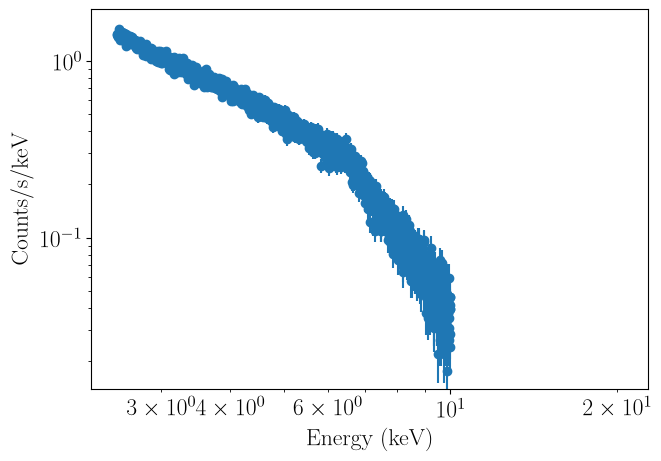

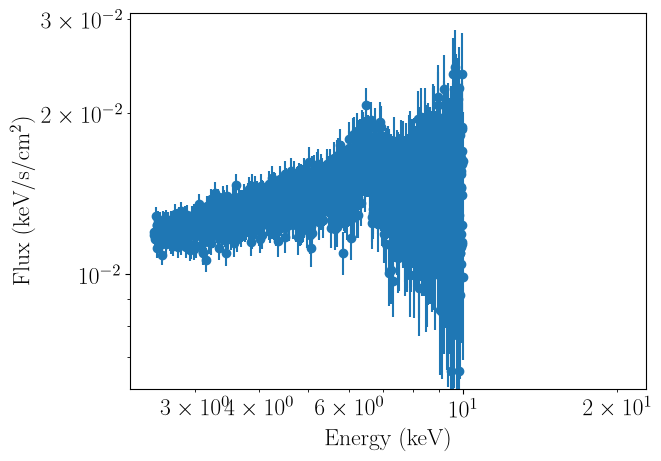

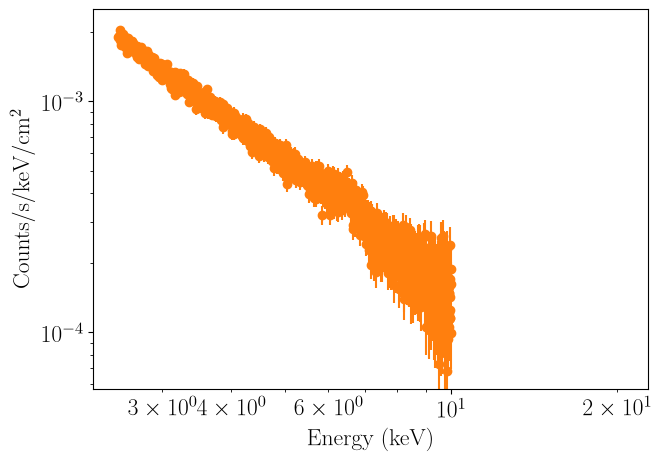

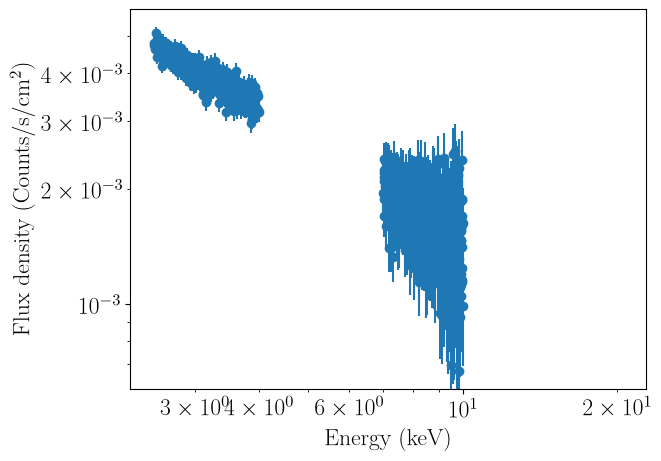

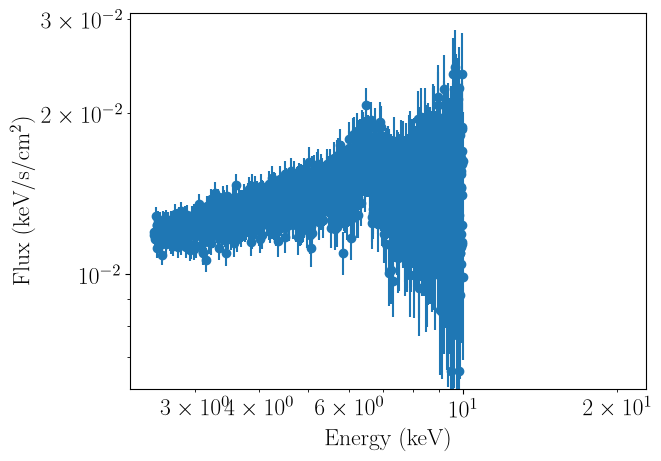

In [13]:
set_plot_style()

spectrum_fit.plot_data(units='data',data_kwargs={"alpha":1})
spectrum_fit.plot_data(units='eeunfold',data_kwargs={"alpha":1})
spectrum_fit.ignore_energies(0,2.5)
spectrum_fit.ignore_energies(10.0,20.0)
spectrum_fit.plot_data(units='unfold',data_kwargs={"alpha":1, "color": "C1"})
spectrum_fit.ignore_energies(4.0,7.0)
spectrum_fit.plot_data(units='eunfold',data_kwargs={"alpha":1})
spectrum_fit.notice_energies(4.0,7.0)
spectrum_fit.plot_data(units='eeunfold',data_kwargs={"alpha":1})

In [14]:
model_library = XSModels.ModelInterface()

model_library.add_models("phabs", "relxill", "powerlaw")

KeyError: "Model 'relxill' is not defined in any loaded library (xspec)"